# Mini-Projet: Planification Robuste sur Grille
## A* + Chaînes de Markov

Ce notebook permet d'exécuter toutes les expériences du mini-projet de manière interactive.

**Objectif:** Planifier un chemin optimal avec A* tout en tenant compte de l'incertitude stochastique modélisée par des chaînes de Markov.

## 1. Imports et Configuration

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Imports des modules du projet
from grid import Grid, create_simple_grid, create_medium_grid, create_hard_grid
from astar import PathFinder, SearchStats
from markov import MarkovChain
from simulation import MonteCarloSimulator
import visualization
import experiments

# Configuration matplotlib
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

print("✓ Imports réussis")

✓ Imports réussis


## 2. Phase 1: Définition de la Grille

In [7]:
# Créer différentes grilles
simple_grid = create_simple_grid()
medium_grid = create_medium_grid()
hard_grid = create_hard_grid()

print("Grille Simple (10x10):")
print(simple_grid)
print("\nGrille Moyenne (15x15):")
print(medium_grid)
print("\nGrille Difficile (20x20):")
print(hard_grid)

Grille Simple (10x10):
..........
.S........
......#...
...#..#...
...#..#...
...#......
..........
..........
........G.
..........

Grille Moyenne (15x15):
.....#.........
.S...#.........
.....#.........
.....#.........
.....#.........
.....#.........
.....#....#....
.....#....#....
.....#....#....
..........#....
.......####....
..........#....
...##.....#....
...#......#..G.
..........#....

Grille Difficile (20x20):
...#.....#.....#....
.S.#.....#.....#....
.........#.....#....
...#.....#.....#....
...#.....#.....#....
...#..#..#.....#....
...#..#..#..#..#....
...#.....#..#..#....
...#..#..#.....#....
...#..#..#..#..#....
...#..#..#..#..#....
...#..#..#..#..#....
...#..#.....#..#....
...#..#..#..#.......
...#..#..#..#..#....
...#..#.....#..#....
......#.....#.......
......#.....#.......
......#.....#.....G.
......#.....#.......


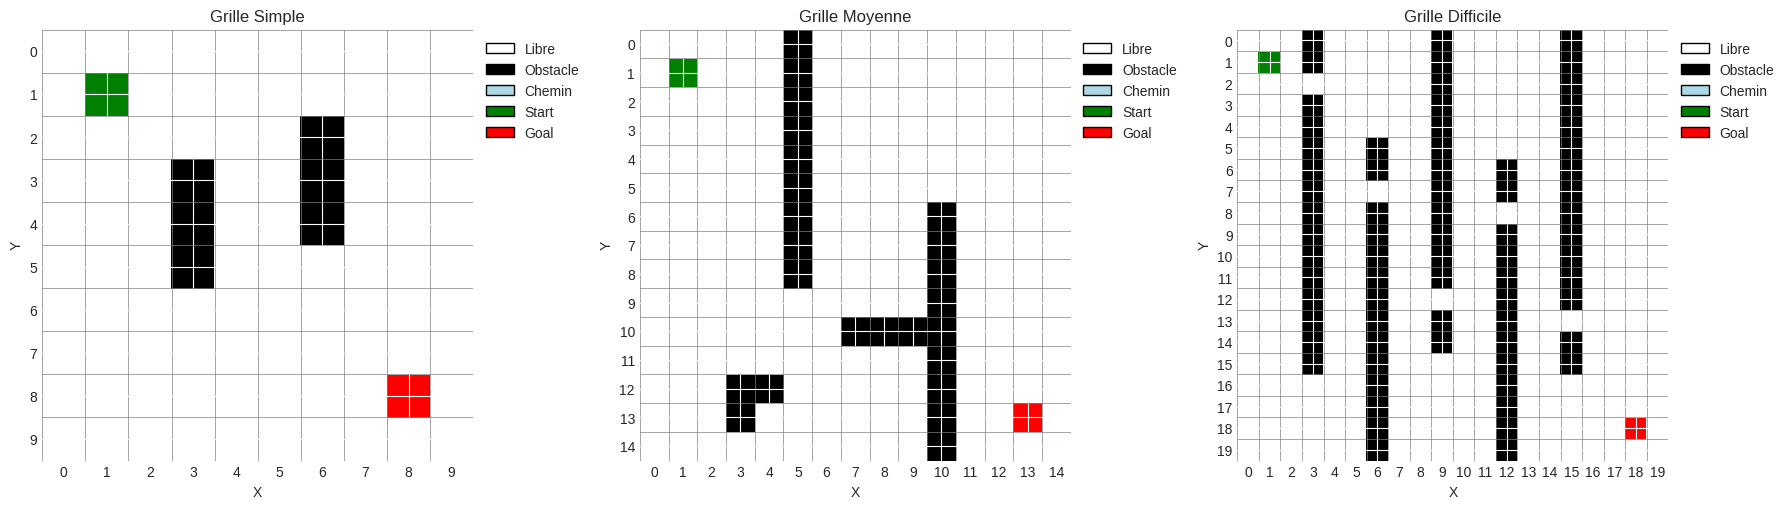

In [24]:
# Visualiser les grilles
vis = Visualizer()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
vis.plot_grid_with_path(simple_grid, title="Grille Simple", ax=axes[0], show=False)
vis.plot_grid_with_path(medium_grid, title="Grille Moyenne", ax=axes[1], show=False)
vis.plot_grid_with_path(hard_grid, title="Grille Difficile", ax=axes[2], show=False)
plt.tight_layout()
plt.show()

## 3. Phase 2: Planification avec A*

### 3.1 A* sur une grille simple

In [8]:
# Utiliser la grille moyenne pour les tests
grid = medium_grid
finder = PathFinder(grid)

# Exécuter A*
stats_astar = finder.astar()

print(f"Succès: {stats_astar.success}")
print(f"Coût du chemin: {stats_astar.cost:.2f}")
print(f"Longueur du chemin: {len(stats_astar.path)}")
print(f"Nœuds développés: {stats_astar.nodes_expanded}")
print(f"Taille max de OPEN: {stats_astar.max_open_size}")
print(f"Temps d'exécution: {stats_astar.execution_time:.4f}s")
print(f"\nChemin: {stats_astar.path}")

Succès: True
Coût du chemin: 32.00
Longueur du chemin: 33
Nœuds développés: 142
Taille max de OPEN: 37
Temps d'exécution: 0.0022s

Chemin: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (2, 5), (2, 6), (2, 7), (3, 7), (3, 8), (4, 8), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9), (9, 8), (9, 7), (9, 6), (9, 5), (10, 5), (11, 5), (12, 5), (12, 6), (12, 7), (13, 7), (13, 8), (13, 9), (13, 10), (13, 11), (13, 12), (13, 13)]


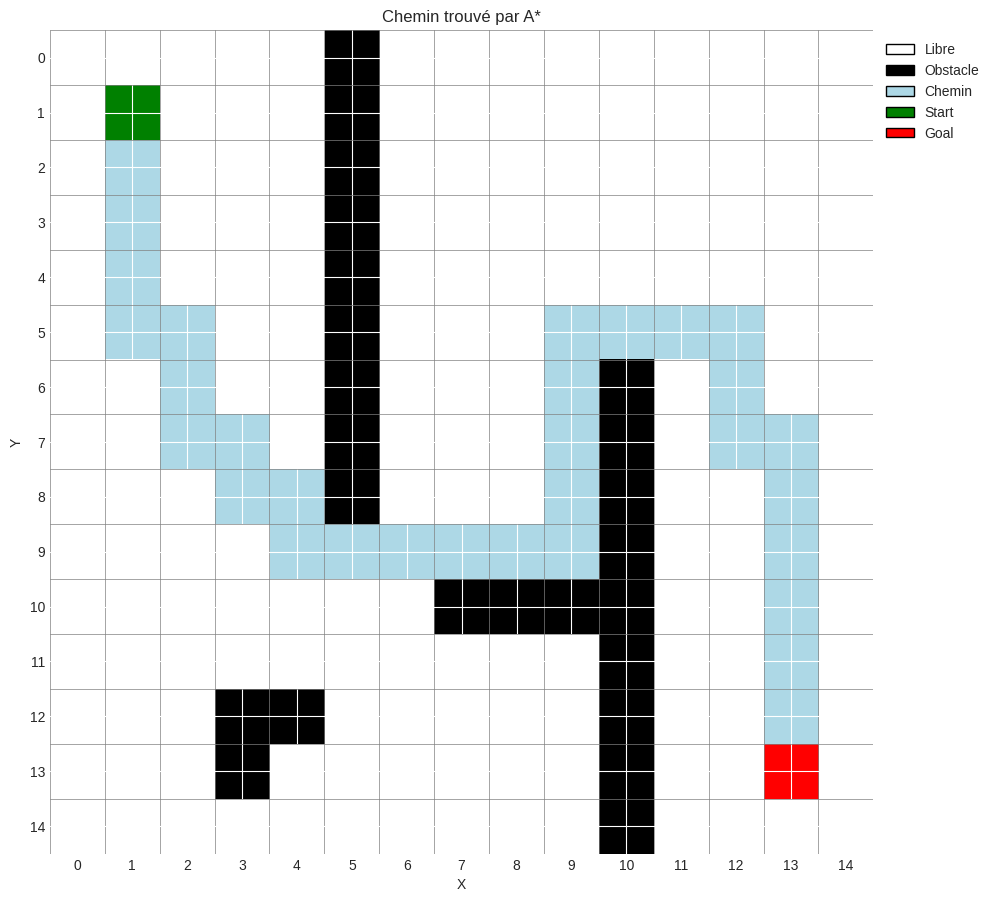

<Axes: title={'center': 'Chemin trouvé par A*'}, xlabel='X', ylabel='Y'>

In [6]:
# Visualiser le chemin A*
vis.plot_grid_with_path(grid, stats_astar.path, title="Chemin trouvé par A*")

### 3.2 Comparaison UCS vs Greedy vs A*

In [9]:
# Comparer les trois algorithmes
stats_ucs = finder.ucs()
stats_greedy = finder.greedy()
stats_astar = finder.astar()

# Tableau comparatif
comparison_data = {
    'Algorithme': ['UCS', 'Greedy', 'A*'],
    'Coût': [stats_ucs.cost, stats_greedy.cost, stats_astar.cost],
    'Longueur': [len(stats_ucs.path), len(stats_greedy.path), len(stats_astar.path)],
    'Nœuds développés': [stats_ucs.nodes_expanded, stats_greedy.nodes_expanded, stats_astar.nodes_expanded],
    'Max OPEN': [stats_ucs.max_open_size, stats_greedy.max_open_size, stats_astar.max_open_size],
    'Temps (s)': [stats_ucs.execution_time, stats_greedy.execution_time, stats_astar.execution_time]
}

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison)

  Algorithme  Coût  Longueur  Nœuds développés  Max OPEN  Temps (s)
0        UCS  32.0        33               196        12   0.002424
1     Greedy  32.0        33                68        48   0.001581
2         A*  32.0        33               142        37   0.002460


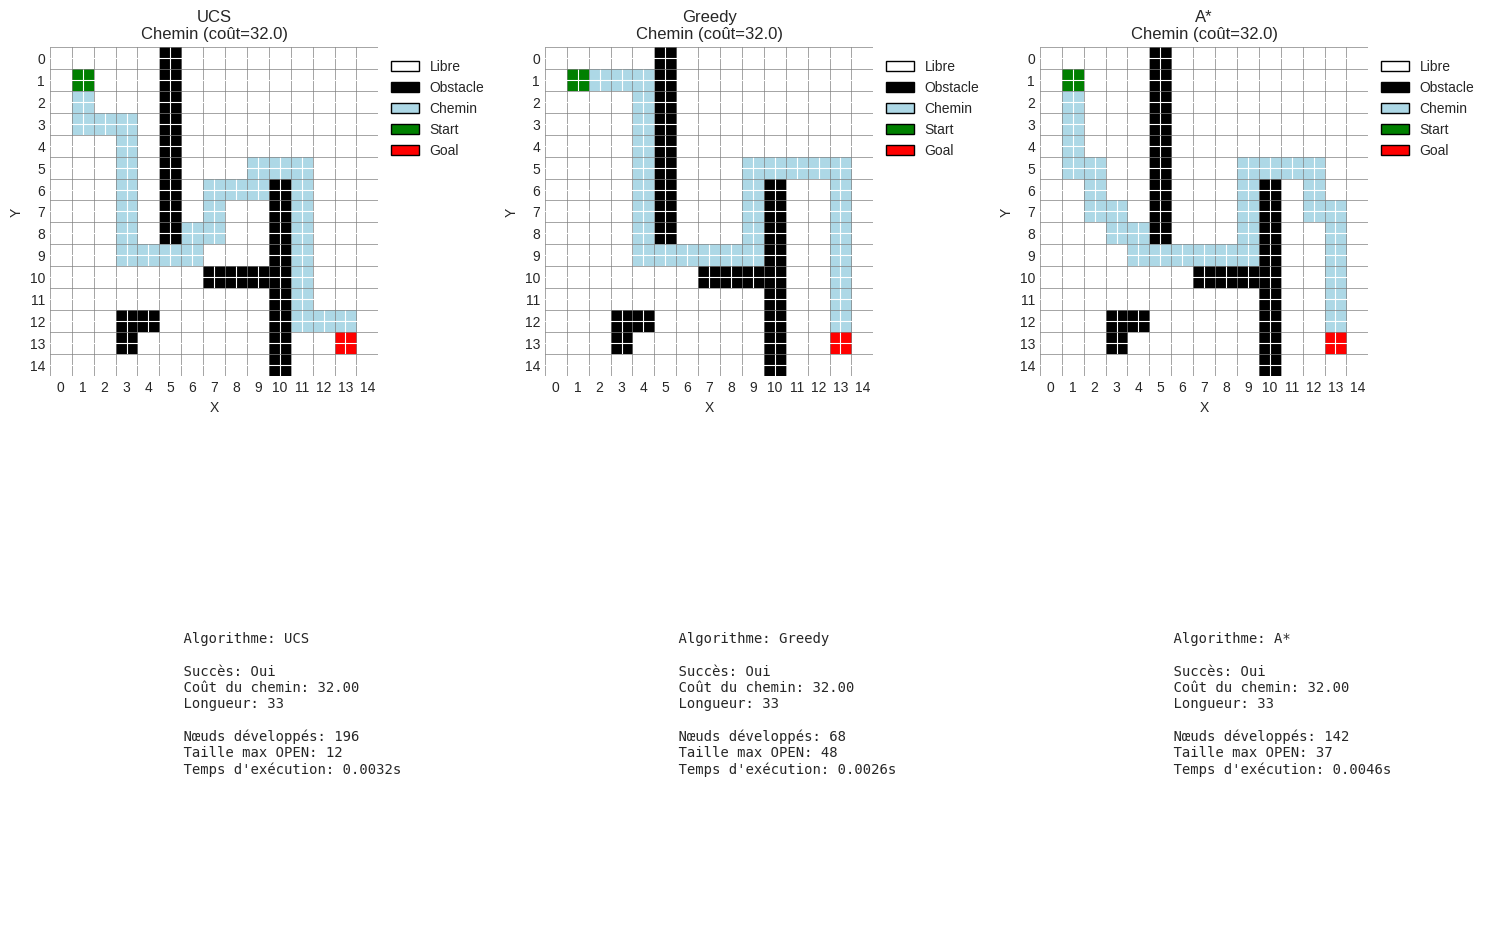

In [8]:
# Visualisation comparative
vis.compare_algorithms({
    'UCS': stats_ucs,
    'Greedy': stats_greedy,
    'A*': stats_astar
}, grid)

## 4. Phase 3: Construction de la Chaîne de Markov

In [11]:
# Créer la chaîne de Markov avec noise = 0.15
noise = 0.15
gamma = 0.9
markov = MarkovChain(grid, gamma=gamma, noise=noise)

print(f"Chaîne de Markov créée avec:")
print(f"  γ (gamma) = {gamma}")
print(f"  ε (noise) = {noise}")
print(f"  Nombre d'états: {len(markov.states)}")
print(f"  Nombre d'actions: {len(markov.actions)}")

Chaîne de Markov créée avec:
  γ (gamma) = 0.9
  ε (noise) = 0.15
  Nombre d'états: 201
  Nombre d'actions: 4


In [13]:
# Exécuter Value Iteration
print("Exécution de Value Iteration...")
vi_result = markov.value_iteration()

print(f"\n=== RÉSULTATS VALUE ITERATION ===")
print(f"Itérations: {vi_result['iterations']}")
print(f"Temps: {vi_result['time']:.4f}s")
print(f"Nombre d'états avec valeur > 0: {sum(1 for v in vi_result['values'].values() if v > 0)}")

# Exécuter Policy Iteration
print("\nExécution de Policy Iteration...")
pi_result = markov.policy_iteration()

print(f"\n=== RÉSULTATS POLICY ITERATION ===")
print(f"Itérations: {pi_result['iterations']}")
print(f"Temps: {pi_result['time']:.4f}s")
print(f"Nombre d'états avec valeur > 0: {sum(1 for v in pi_result['values'].values() if v > 0)}")

Exécution de Value Iteration...

=== RÉSULTATS VALUE ITERATION ===
Itérations: 50
Temps: 18.5536s
Nombre d'états avec valeur > 0: 147

Exécution de Policy Iteration...

=== RÉSULTATS POLICY ITERATION ===
Itérations: 7
Temps: 17.1612s
Nombre d'états avec valeur > 0: 147


## 5. Phase 4: Analyse de Markov

In [11]:
# # Analyse complète (MarkovAnalysis non implémenté)
# analysis = markov.analyze()
# 
# print("=== ANALYSE DE LA CHAÎNE DE MARKOV ===")
# print(f"\nMatrice P: {analysis.transition_matrix.shape}")
# print(f"Stochastique: {analysis.is_stochastic}")
# print(f"\nÉtats absorbants: {len(analysis.absorbing_states)}")
# for idx in analysis.absorbing_states:
#     print(f"  - {analysis.index_to_state[idx]}")
# 
# print(f"\nÉtats transitoires: {len(analysis.transient_states)}")
# print(f"États récurrents: {len(analysis.recurrent_states)}")

print("⚠️  Section 'Analyse de la chaîne de Markov' commentée")
print("    (MarkovAnalysis non implémenté)")
print("    Décommentez une fois que la classe MarkovAnalysis sera créée.")

=== ANALYSE DE LA CHAÎNE DE MARKOV ===

Matrice P: (83, 83)
Stochastique: True

États absorbants: 50
  - (0, 1)
  - (0, 2)
  - (0, 3)
  - (0, 4)
  - (0, 5)
  - (1, 0)
  - (1, 6)
  - (1, 7)
  - (10, 4)
  - (11, 4)
  - (11, 6)
  - (11, 7)
  - (12, 10)
  - (12, 11)
  - (12, 12)
  - (12, 13)
  - (12, 4)
  - (12, 8)
  - (12, 9)
  - (13, 14)
  - (13, 5)
  - (13, 6)
  - (14, 10)
  - (14, 11)
  - (14, 12)
  - (14, 13)
  - (14, 7)
  - (14, 8)
  - (14, 9)
  - (2, 1)
  - (2, 2)
  - (2, 3)
  - (2, 4)
  - (2, 8)
  - (3, 5)
  - (3, 6)
  - (3, 9)
  - (4, 10)
  - (4, 7)
  - (5, 10)
  - (6, 10)
  - (6, 8)
  - (7, 8)
  - (8, 5)
  - (8, 6)
  - (8, 7)
  - (8, 8)
  - (9, 4)
  - FAIL
  - GOAL

États transitoires: 15
États récurrents: 68


In [12]:
# # Calculer π(n) pour différentes valeurs de n (MarkovAnalysis non implémenté)
# start_idx = analysis.state_to_index[str(grid.start)]
# goal_idx = analysis.state_to_index[markov.GOAL_STATE]
# 
# # Distribution initiale
# pi0 = np.zeros(len(analysis.state_to_index))
# pi0[start_idx] = 1.0
# 
# # Calculer pour n = 1, 5, 10, 20, 50, 100
# steps = [1, 5, 10, 20, 50, 100]
# probs_over_time = []
# 
# print("\n=== ÉVOLUTION DE π(n) ===")
# print(f"{'n':>5s} | {'P(GOAL)':>10s}")
# print("-" * 20)
# 
# for n in steps:
#     pi_n = markov.compute_distribution_at_step(P, pi0, n)
#     prob_goal = pi_n[goal_idx]
#     probs_over_time.append(prob_goal)
#     print(f"{n:>5d} | {prob_goal:>10.4f}")

print("⚠️  Section 'Évolution de π(n)' commentée")
print("    (MarkovAnalysis et méthodes auxiliaires non implémentées)")


=== ÉVOLUTION DE π(n) ===
    n |    P(GOAL)
--------------------
    1 |     0.0000
    5 |     0.0000
   10 |     0.0000
   20 |     0.0000
   50 |     0.0260
  100 |     0.0260


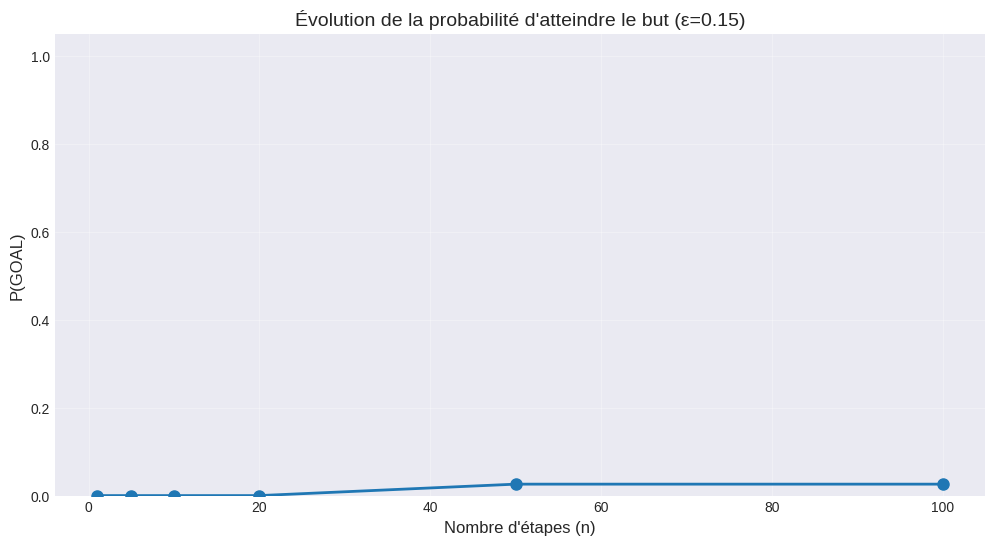

In [13]:
# # Visualiser l'évolution de π(n)
# plt.figure(figsize=(12, 6))
# plt.plot(steps, probs_over_time, 'o-', linewidth=2, markersize=8)
# plt.xlabel('Nombre d\'étapes (n)', fontsize=12)
# plt.ylabel('P(GOAL)', fontsize=12)
# plt.title(f'Évolution de la probabilité d\'atteindre le but (ε={epsilon})', fontsize=14)
# plt.grid(True, alpha=0.3)
# plt.ylim([0, 1.05])
# plt.show()

print("⚠️  Visualisation de π(n) commentée")
print("    (Dépend des cellules précédentes non implémentées)")

In [14]:
# # Probabilités et temps d'absorption
# if analysis.absorption_probabilities is not None:
#     print("\n=== ANALYSE D'ABSORPTION ===")
#     absorbing_list = sorted(list(analysis.absorbing_states))
#     
#     print(f"\nDepuis START:")
#     for i, abs_idx in enumerate(absorbing_list):
#         prob = analysis.absorption_probabilities[start_idx, i]
#         print(f"  P({analysis.index_to_state[abs_idx]}) = {prob:.4f}")
#     
#     print(f"\nTemps moyen d'absorption: {analysis.expected_absorption_time[start_idx]:.2f} étapes")

print("⚠️  Section 'Analyse d'absorption' commentée")
print("    (MarkovAnalysis non implémenté)")


=== ANALYSE D'ABSORPTION ===

Depuis START:
  P((0, 1)) = 0.0750
  P((0, 2)) = 0.0638
  P((0, 3)) = 0.0542
  P((0, 4)) = 0.0494
  P((0, 5)) = 0.0000
  P((1, 0)) = 0.0000
  P((1, 6)) = 0.0797
  P((1, 7)) = 0.0000
  P((10, 4)) = 0.0095
  P((11, 4)) = 0.0086
  P((11, 6)) = 0.0153
  P((11, 7)) = 0.0000
  P((12, 10)) = 0.0032
  P((12, 11)) = 0.0027
  P((12, 12)) = 0.0023
  P((12, 13)) = 0.0000
  P((12, 4)) = 0.0000
  P((12, 8)) = 0.0105
  P((12, 9)) = 0.0037
  P((13, 14)) = 0.0000
  P((13, 5)) = 0.0073
  P((13, 6)) = 0.0067
  P((14, 10)) = 0.0032
  P((14, 11)) = 0.0027
  P((14, 12)) = 0.0023
  P((14, 13)) = 0.0000
  P((14, 7)) = 0.0052
  P((14, 8)) = 0.0044
  P((14, 9)) = 0.0037
  P((2, 1)) = 0.0750
  P((2, 2)) = 0.0638
  P((2, 3)) = 0.0542
  P((2, 4)) = 0.0494
  P((2, 8)) = 0.0318
  P((3, 5)) = 0.0381
  P((3, 6)) = 0.0348
  P((3, 9)) = 0.0266
  P((4, 10)) = 0.0223
  P((4, 7)) = 0.0290
  P((5, 10)) = 0.0205
  P((6, 10)) = 0.0174
  P((6, 8)) = 0.0174
  P((7, 8)) = 0.0160
  P((8, 5)) = 0.000

## 6. Phase 5: Simulation Monte-Carlo

In [15]:
# Créer le simulateur
simulator = MonteCarloSimulator(grid, markov)

# Exécuter N simulations
n_simulations = 100  # Réduit pour performance
max_steps = 500
print(f"Exécution de {n_simulations} simulations (max {max_steps} étapes)...")

# Simuler plusieurs épisodes
trajectories = []
rewards = []
successes = 0
steps_list = []

for i in range(n_simulations):
    episode = simulator.simulate_episode(grid.start, max_steps=max_steps, use_policy=True)
    trajectories.append(episode['trajectory'])
    rewards.append(episode['reward'])
    if episode['success']:
        successes += 1
    steps_list.append(episode['steps'])
    
    if (i + 1) % 20 == 0:
        print(f"  {i + 1}/{n_simulations} simulations terminées...")

print(f"\n=== RÉSULTATS DE SIMULATION ===")
print(f"Nombre de simulations: {n_simulations}")
print(f"Succès: {successes} ({100*successes/n_simulations:.1f}%)")
print(f"Échecs: {n_simulations - successes} ({100*(n_simulations-successes)/n_simulations:.1f}%)")
print(f"\nÉtapes moyennes: {np.mean(steps_list):.2f} ± {np.std(steps_list):.2f}")
print(f"Récompense moyenne: {np.mean(rewards):.2f} ± {np.std(rewards):.2f}")

Exécution de 100 simulations (max 500 étapes)...
  20/100 simulations terminées...
  40/100 simulations terminées...
  60/100 simulations terminées...
  80/100 simulations terminées...
  100/100 simulations terminées...

=== RÉSULTATS DE SIMULATION ===
Nombre de simulations: 100
Succès: 0 (0.0%)
Échecs: 100 (100.0%)

Étapes moyennes: 500.00 ± 0.00
Récompense moyenne: -500.00 ± 0.00


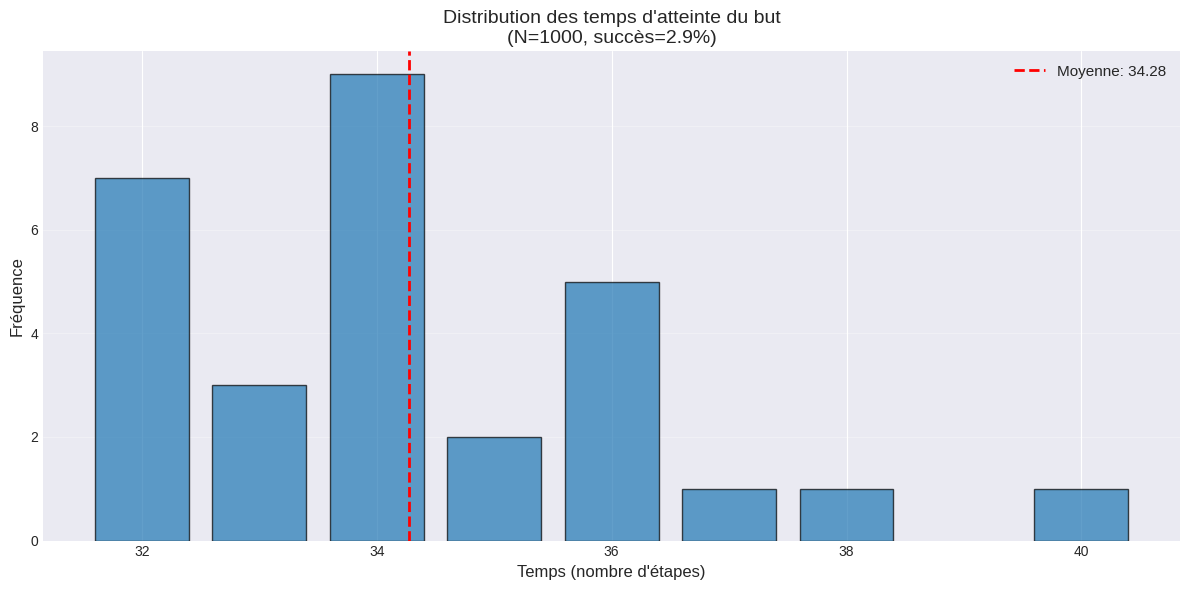

In [17]:
# Visualiser la distribution des temps
vis.plot_time_distribution(results)

Affichage de 3 trajectoires échantillons...


Affichage de 3 trajectoires échantillons...


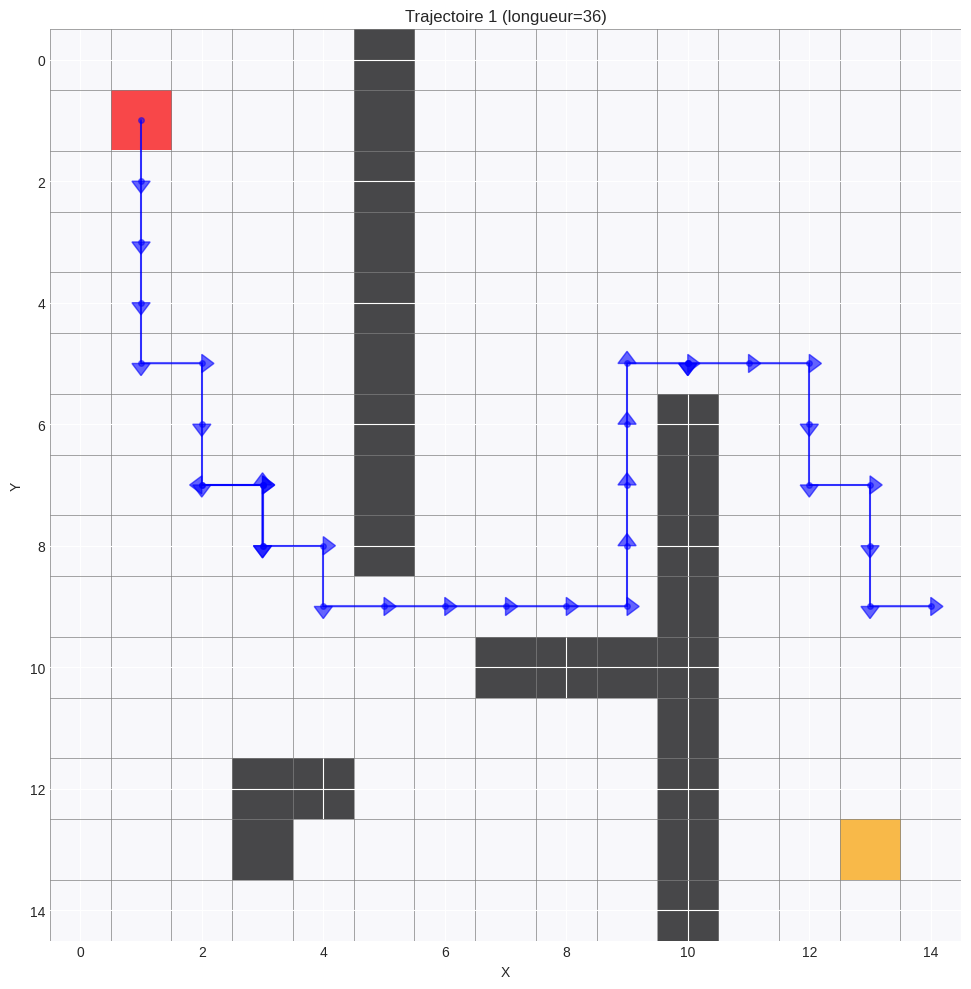

Affichage de 3 trajectoires échantillons...


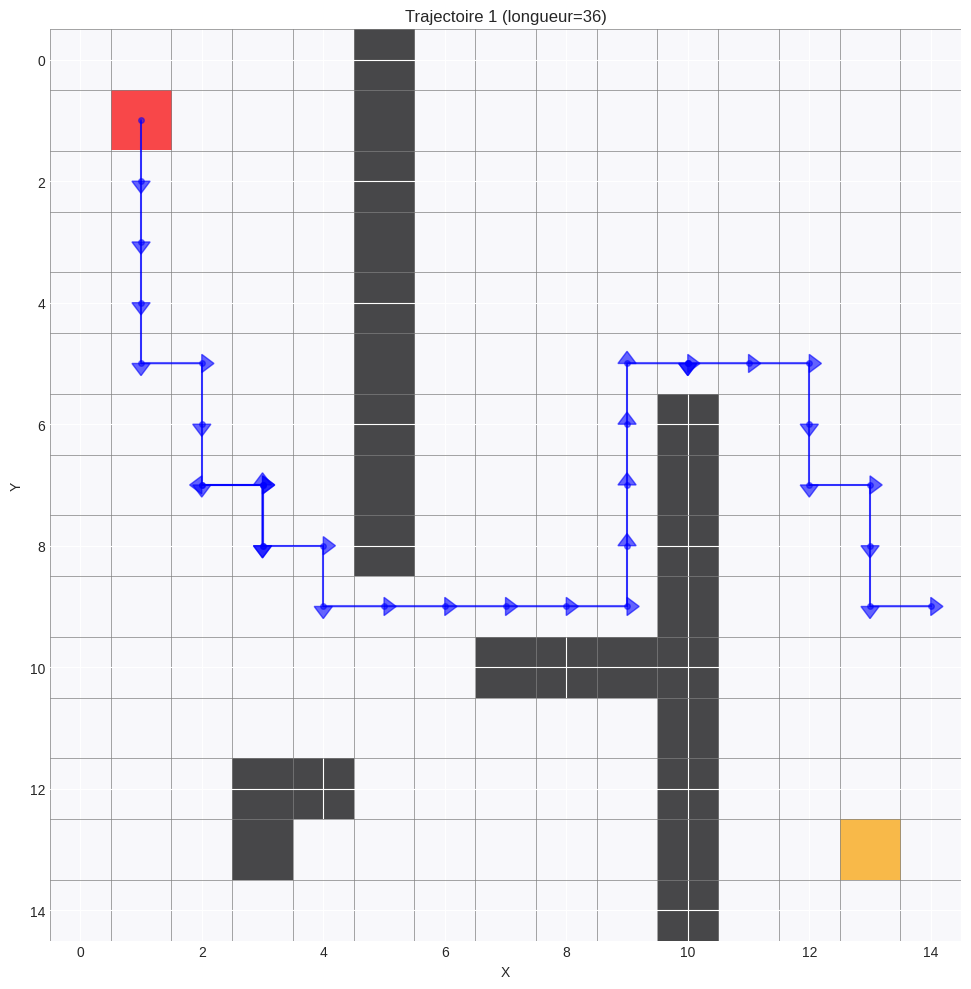

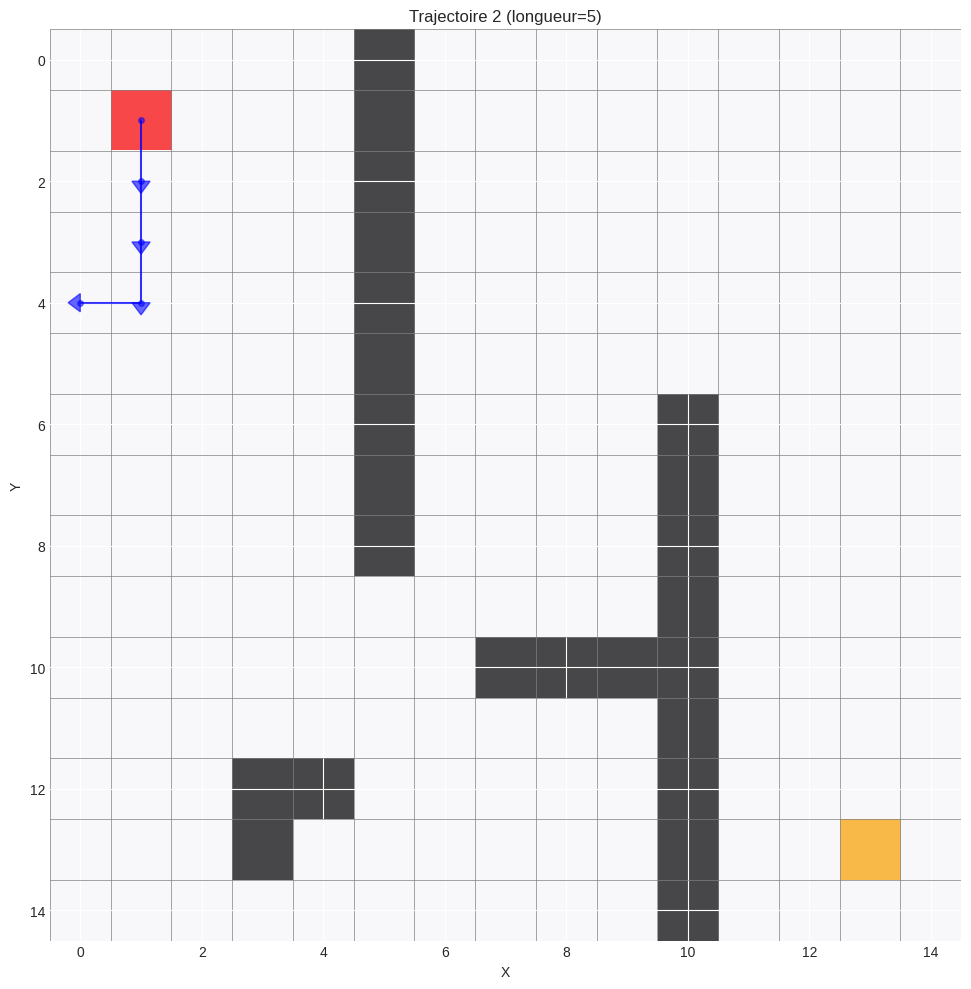

Affichage de 3 trajectoires échantillons...


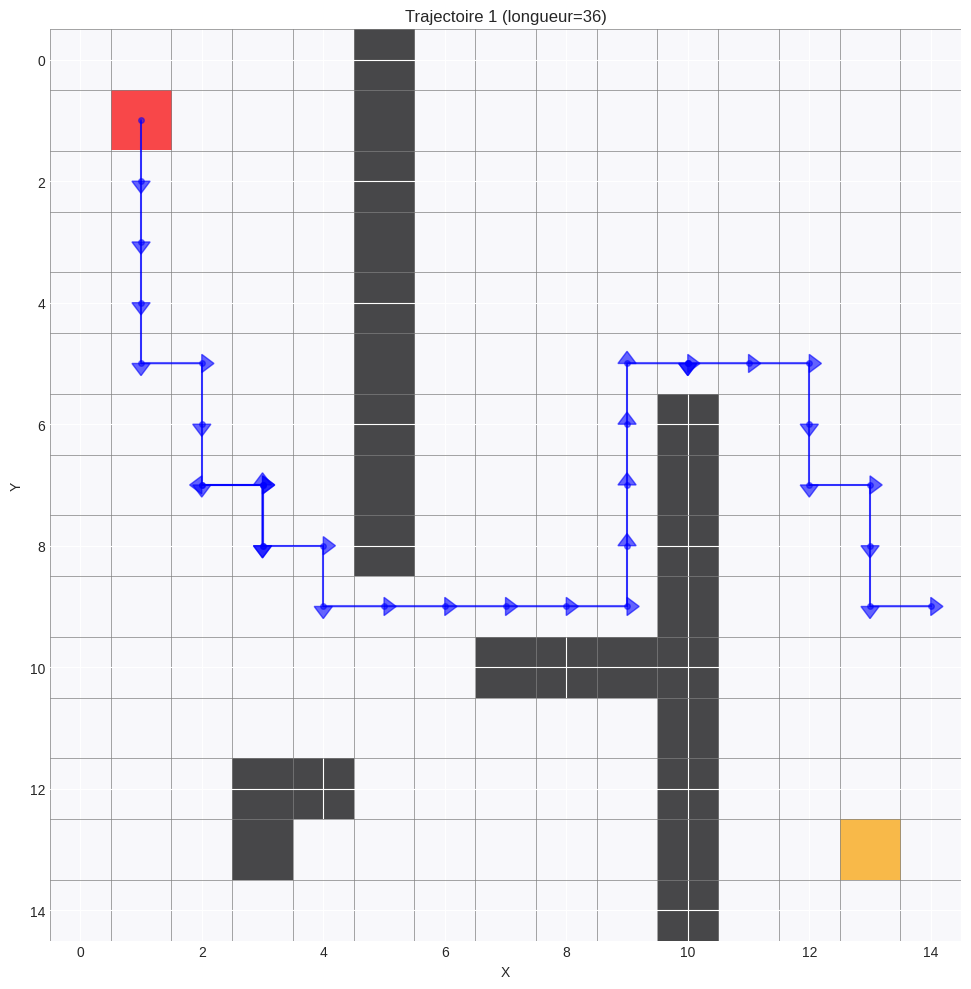

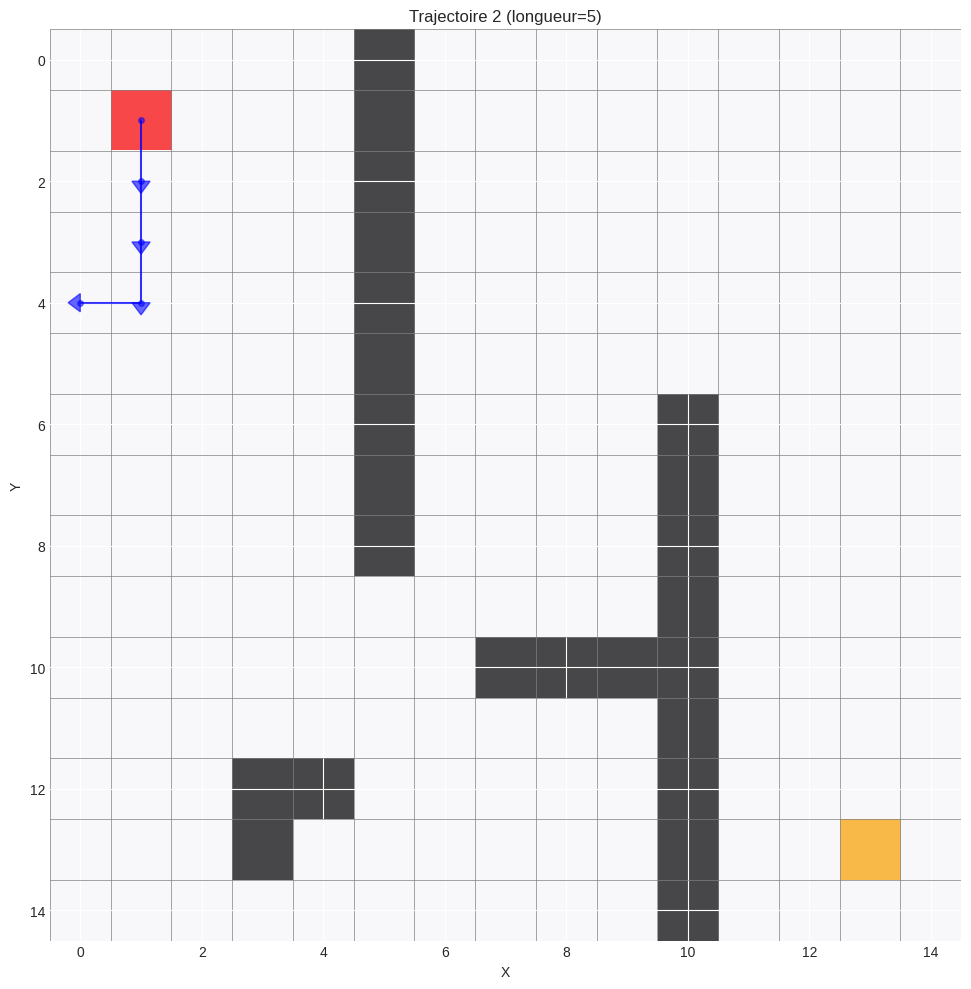

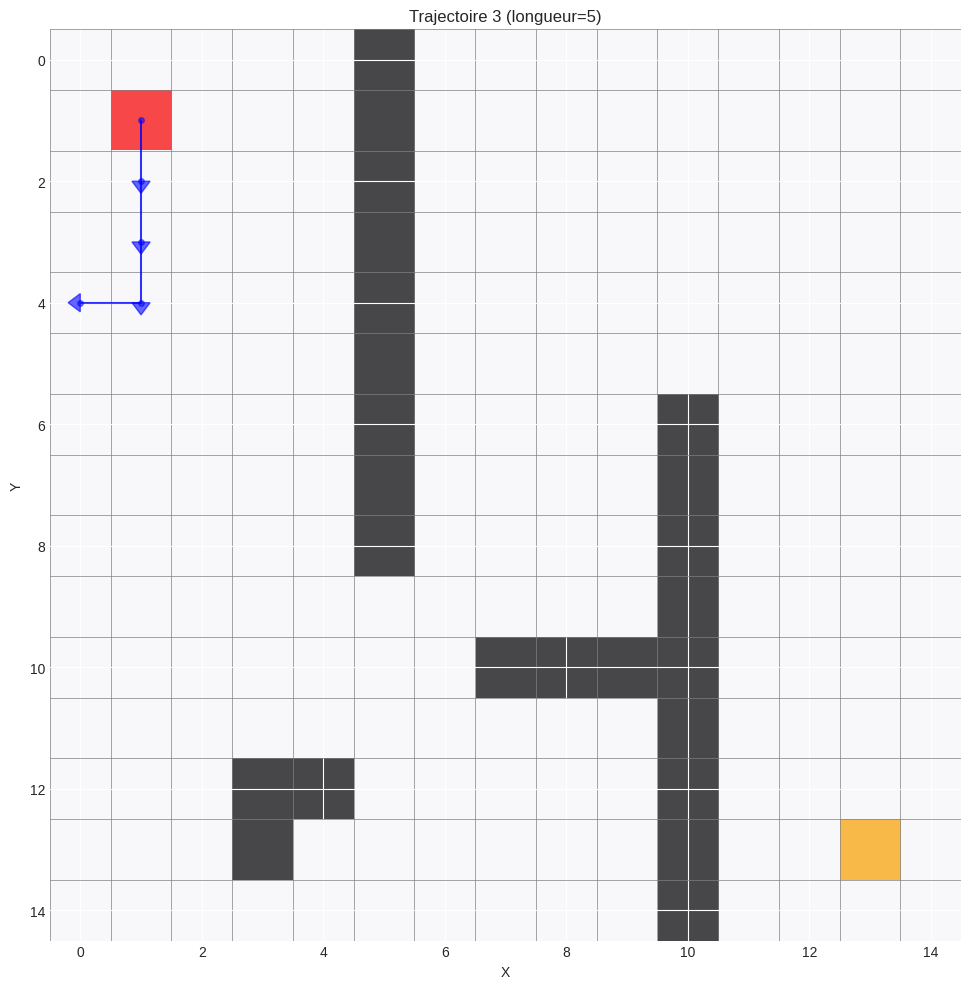

In [16]:
# Visualiser quelques trajectoires
print(f"Affichage de 3 trajectoires échantillons...")
for i in range(min(3, len(results.trajectories_sample))):
    vis.plot_trajectory(grid, results.trajectories_sample[i], 
                       title=f"Trajectoire {i+1} (longueur={len(results.trajectories_sample[i])})")

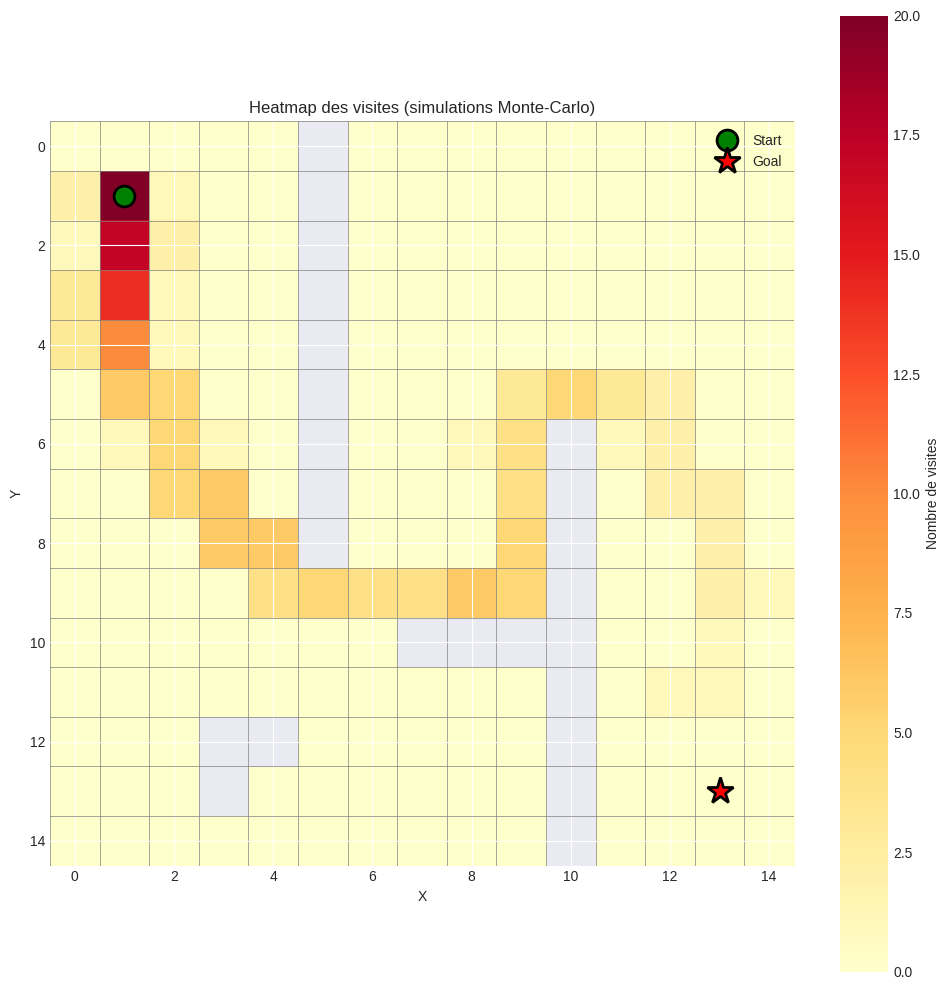

In [18]:
# Heatmap des visites
vis.plot_heatmap_visits(grid, results.trajectories_sample)

### 6.1 Comparaison Empirique vs Théorique

In [19]:
# Comparer avec les prédictions théoriques
comparison = simulator.compare_with_theoretical(n_simulations=1000, max_steps_analysis=100)

print("=== COMPARAISON EMPIRIQUE VS THÉORIQUE ===")
print(f"\nTaux de succès:")
print(f"  Empirique: {comparison['comparison']['empirical_success_rate']:.4f}")
print(f"  Théorique: {comparison['comparison']['theoretical_success_rate']:.4f}")
print(f"\nTemps moyen:")
print(f"  Empirique: {comparison['comparison']['empirical_mean_time']:.2f}")
print(f"  Théorique: {comparison['comparison']['theoretical_mean_time']:.2f}")

=== COMPARAISON EMPIRIQUE VS THÉORIQUE ===

Taux de succès:
  Empirique: 0.0370
  Théorique: 0.0260

Temps moyen:
  Empirique: 34.92
  Théorique: 9.18


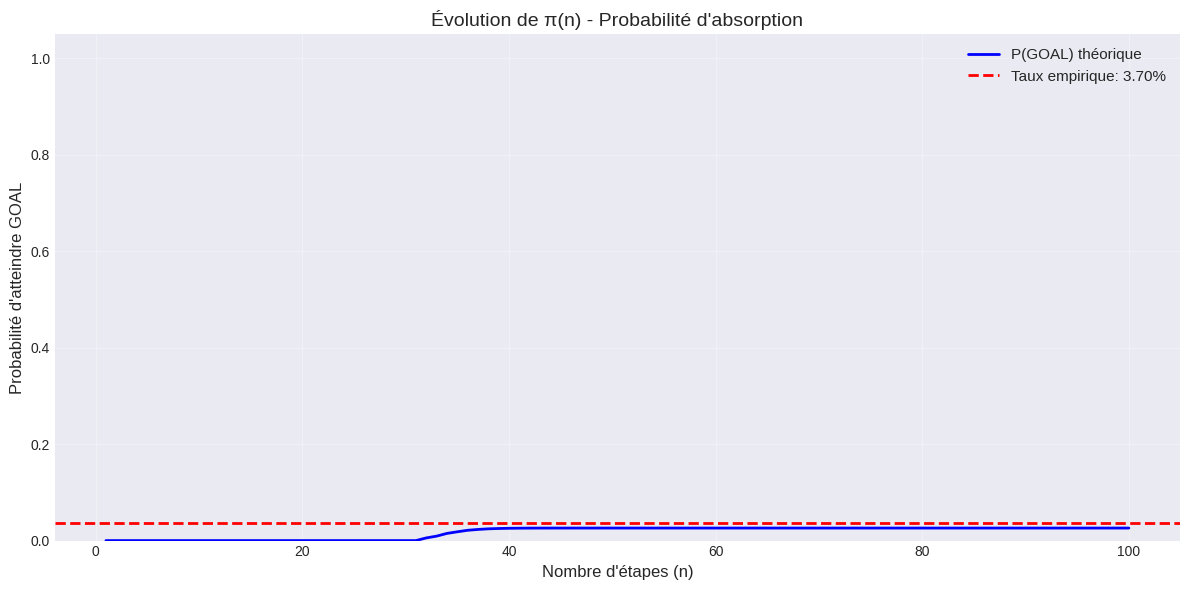

In [20]:
# Visualiser la convergence théorique
vis.plot_markov_probabilities(
    comparison['theoretical_probs'],
    comparison['comparison']['empirical_success_rate']
)

## 7. Expériences Recommandées

### E.1: Comparaison UCS vs Greedy vs A*

EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


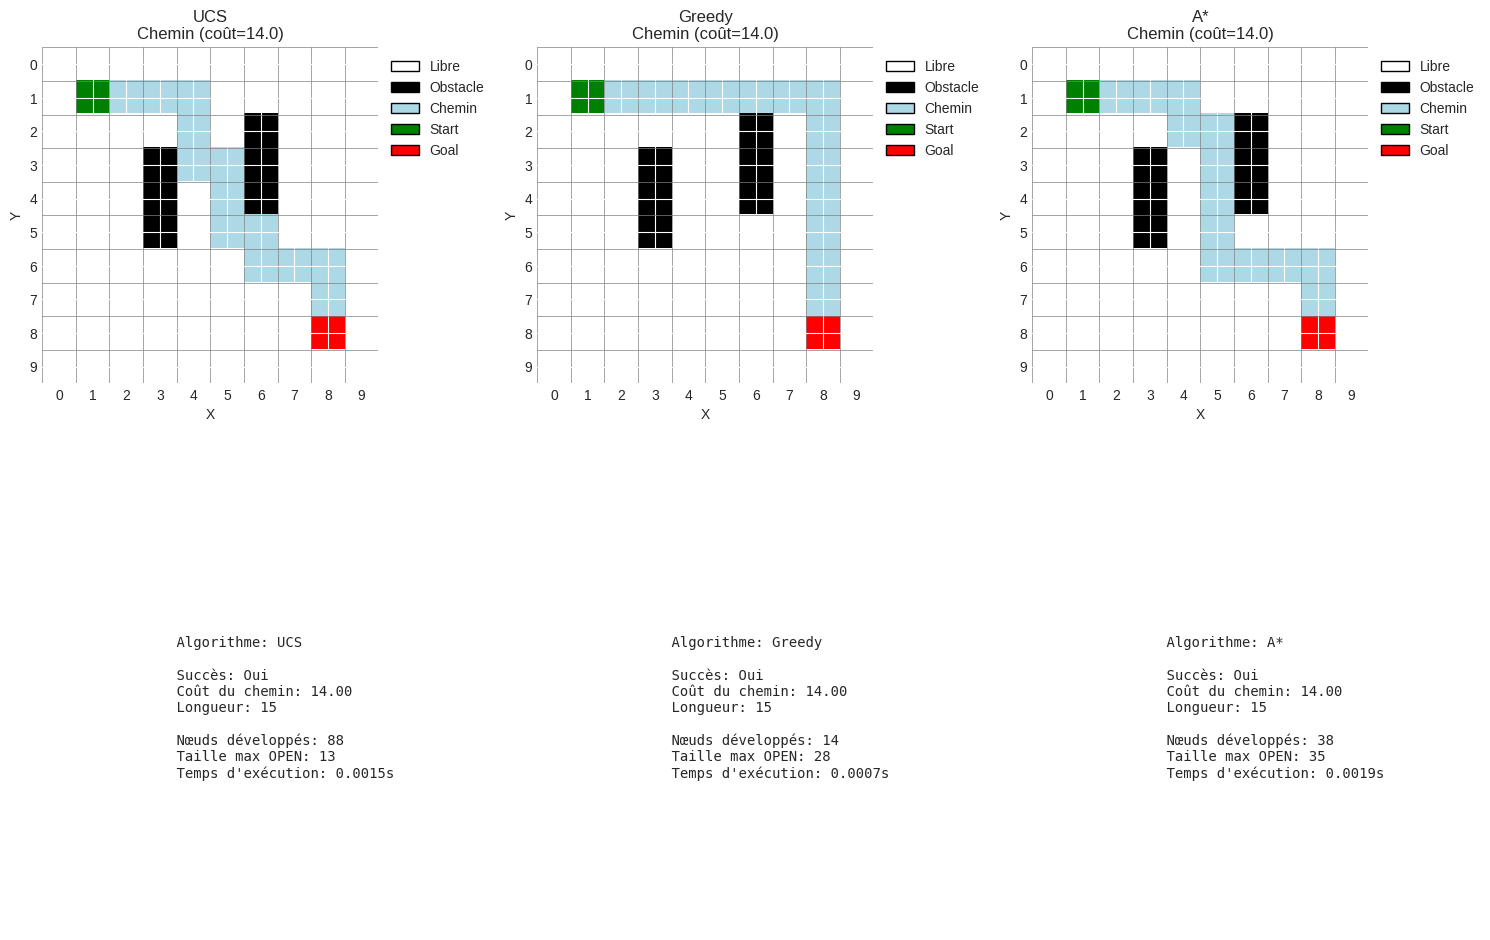

EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


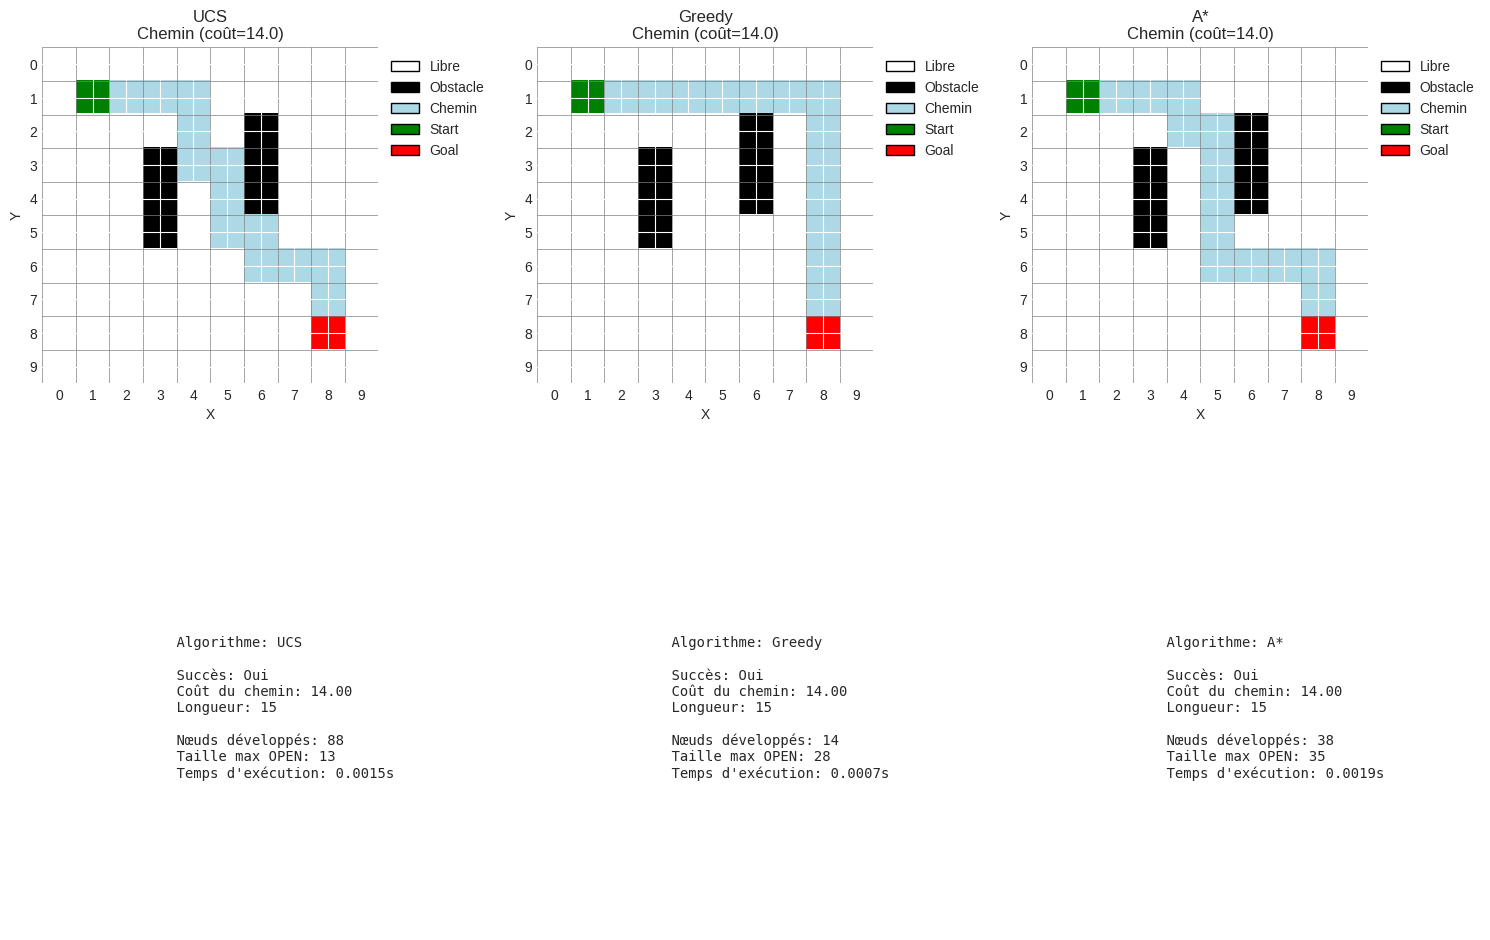


--- Grille Moyenne (15x15) ---
UCS     : coût=  32.0, nœuds=  196, temps=0.0033s
Greedy  : coût=  32.0, nœuds=   68, temps=0.0019s
A*      : coût=  32.0, nœuds=  142, temps=0.0043s
  → Visualisation pour grille Moyenne...


EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


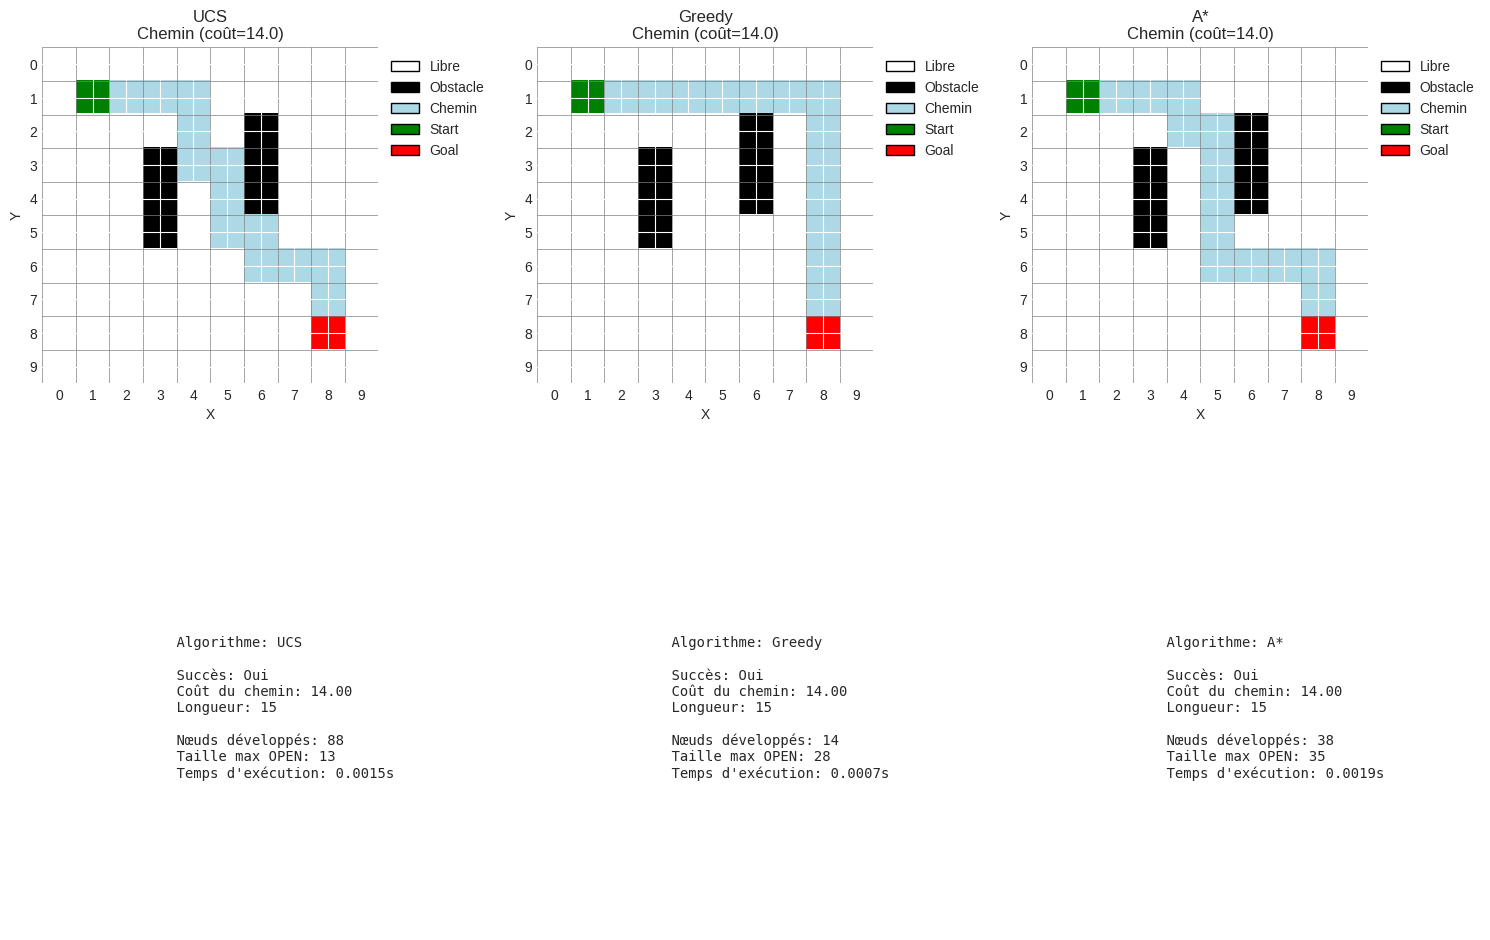


--- Grille Moyenne (15x15) ---
UCS     : coût=  32.0, nœuds=  196, temps=0.0033s
Greedy  : coût=  32.0, nœuds=   68, temps=0.0019s
A*      : coût=  32.0, nœuds=  142, temps=0.0043s
  → Visualisation pour grille Moyenne...


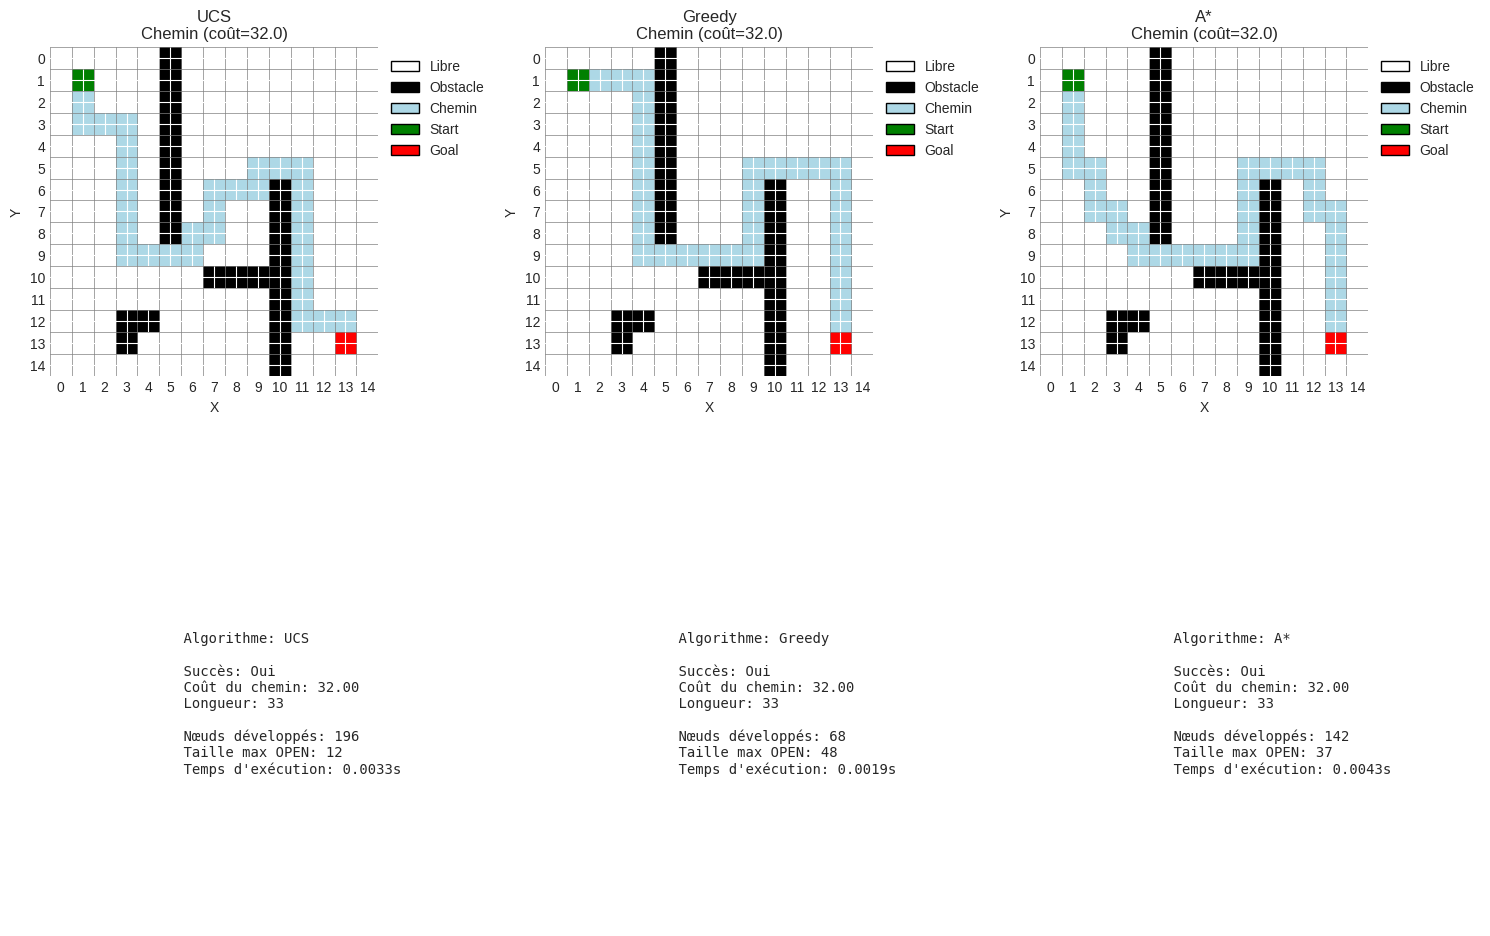

EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


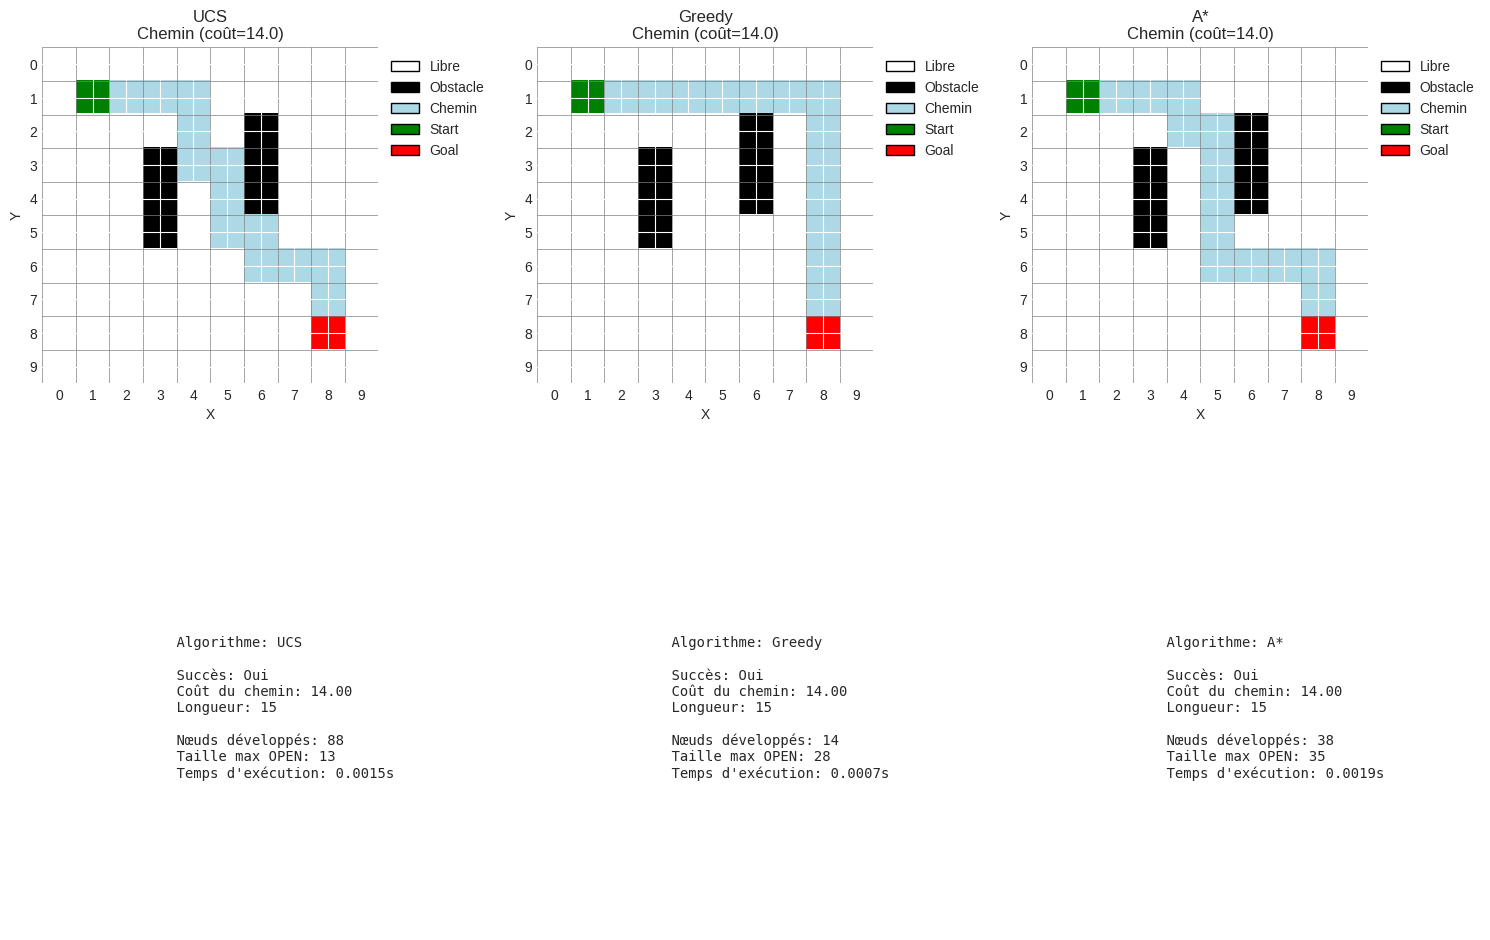


--- Grille Moyenne (15x15) ---
UCS     : coût=  32.0, nœuds=  196, temps=0.0033s
Greedy  : coût=  32.0, nœuds=   68, temps=0.0019s
A*      : coût=  32.0, nœuds=  142, temps=0.0043s
  → Visualisation pour grille Moyenne...


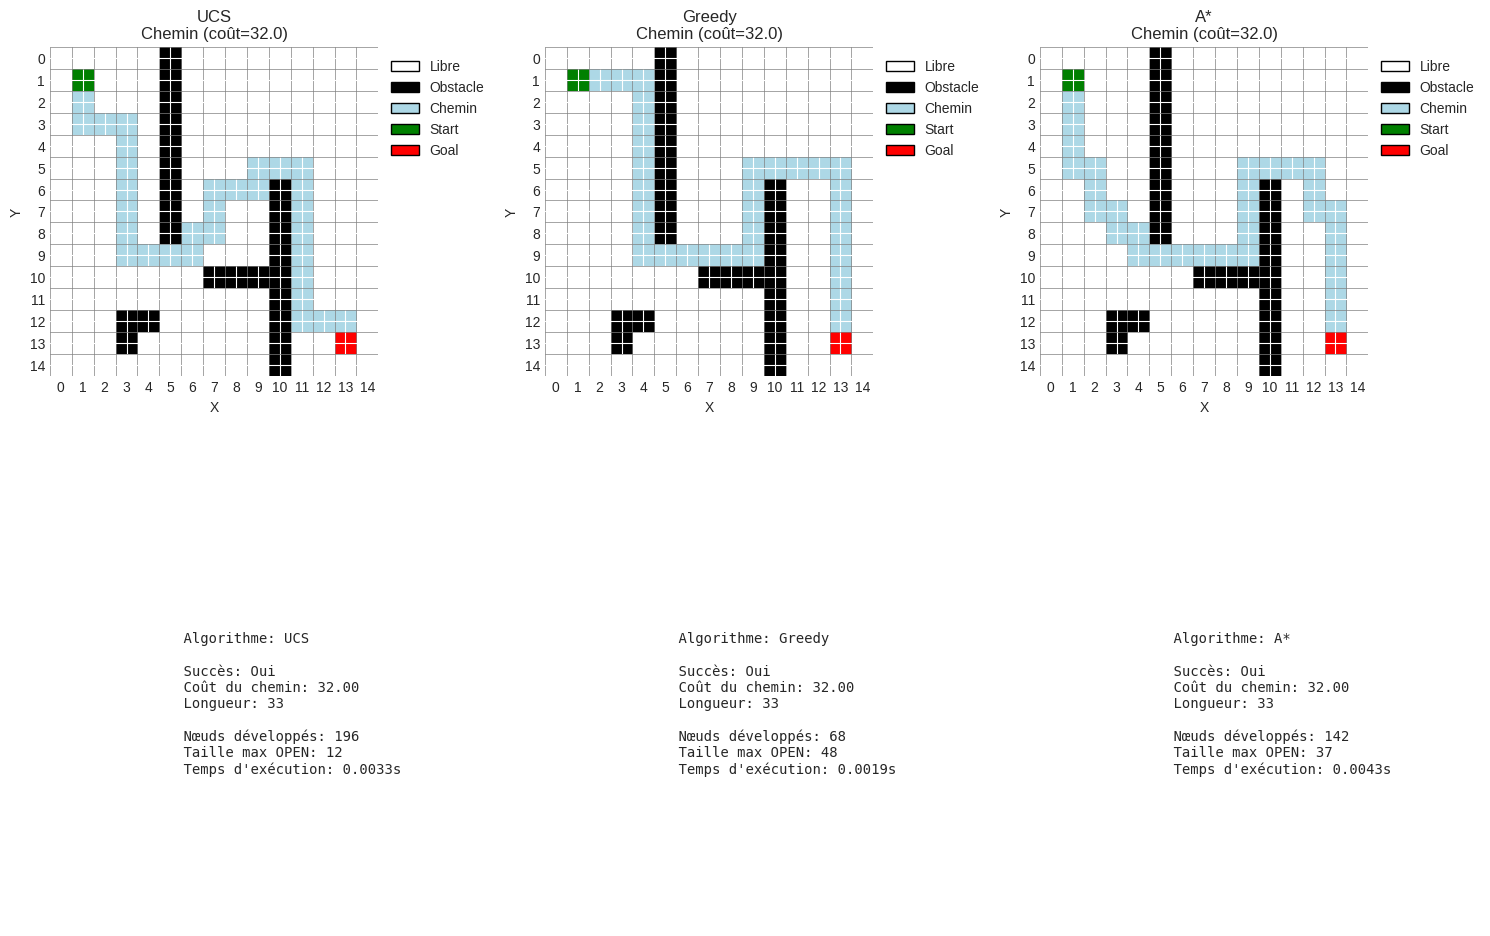


--- Grille Difficile (20x20) ---
UCS     : coût=  42.0, nœuds=  290, temps=0.0021s
Greedy  : coût=  42.0, nœuds=   79, temps=0.0008s
A*      : coût=  42.0, nœuds=  220, temps=0.0031s
  → Visualisation pour grille Difficile...


EXPÉRIENCE E.1: Comparaison UCS vs Greedy vs A*

--- Grille Facile (10x10) ---
UCS     : coût=  14.0, nœuds=   88, temps=0.0015s
Greedy  : coût=  14.0, nœuds=   14, temps=0.0007s
A*      : coût=  14.0, nœuds=   38, temps=0.0019s
  → Visualisation pour grille Facile...


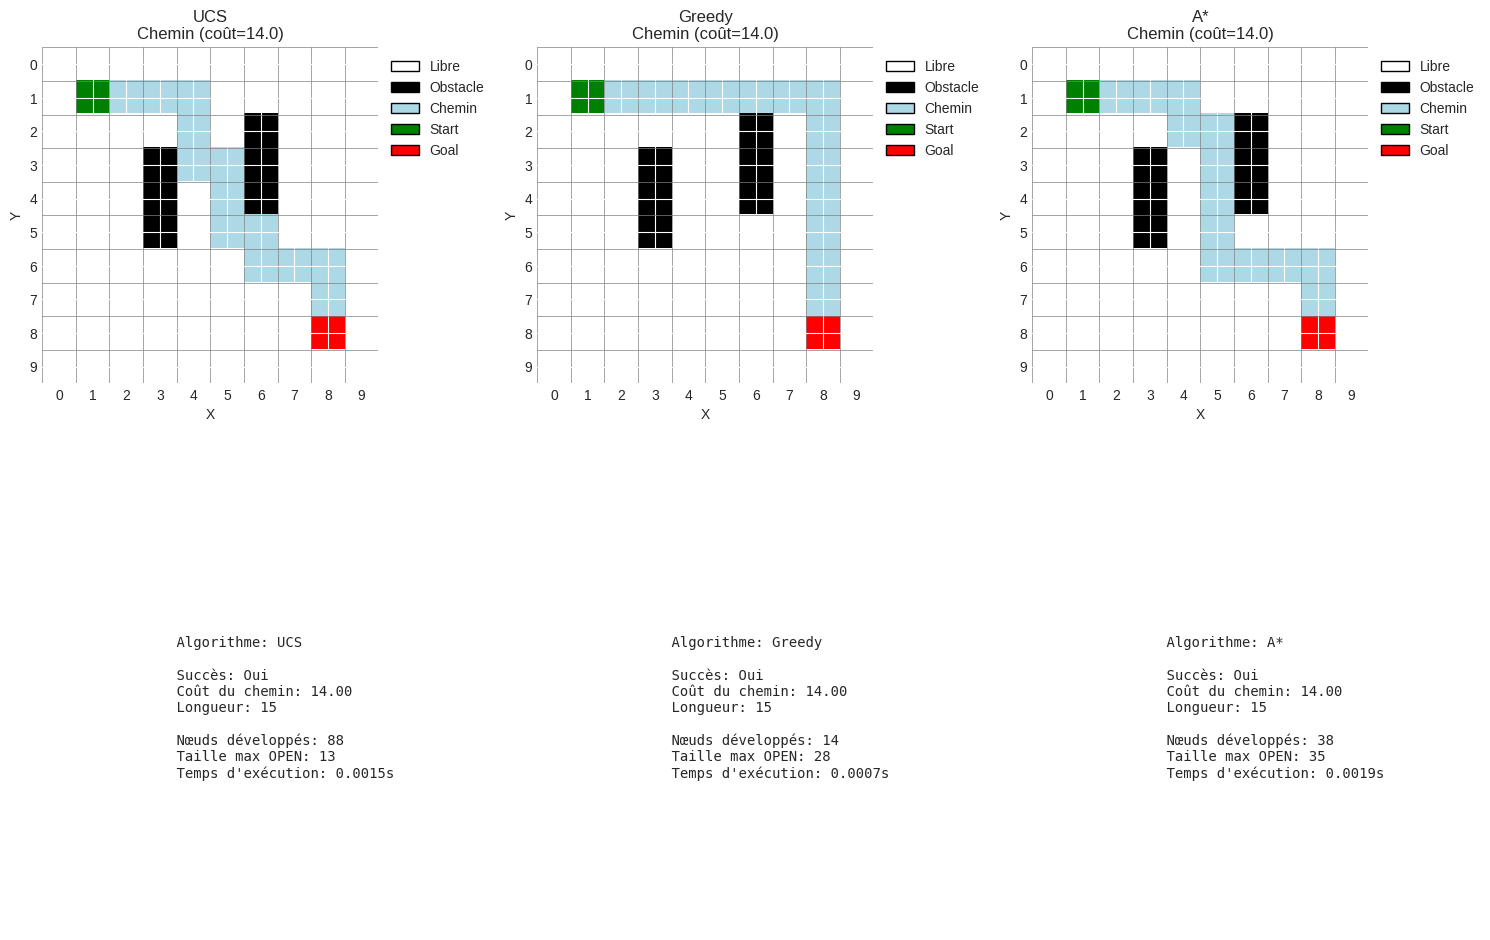


--- Grille Moyenne (15x15) ---
UCS     : coût=  32.0, nœuds=  196, temps=0.0033s
Greedy  : coût=  32.0, nœuds=   68, temps=0.0019s
A*      : coût=  32.0, nœuds=  142, temps=0.0043s
  → Visualisation pour grille Moyenne...


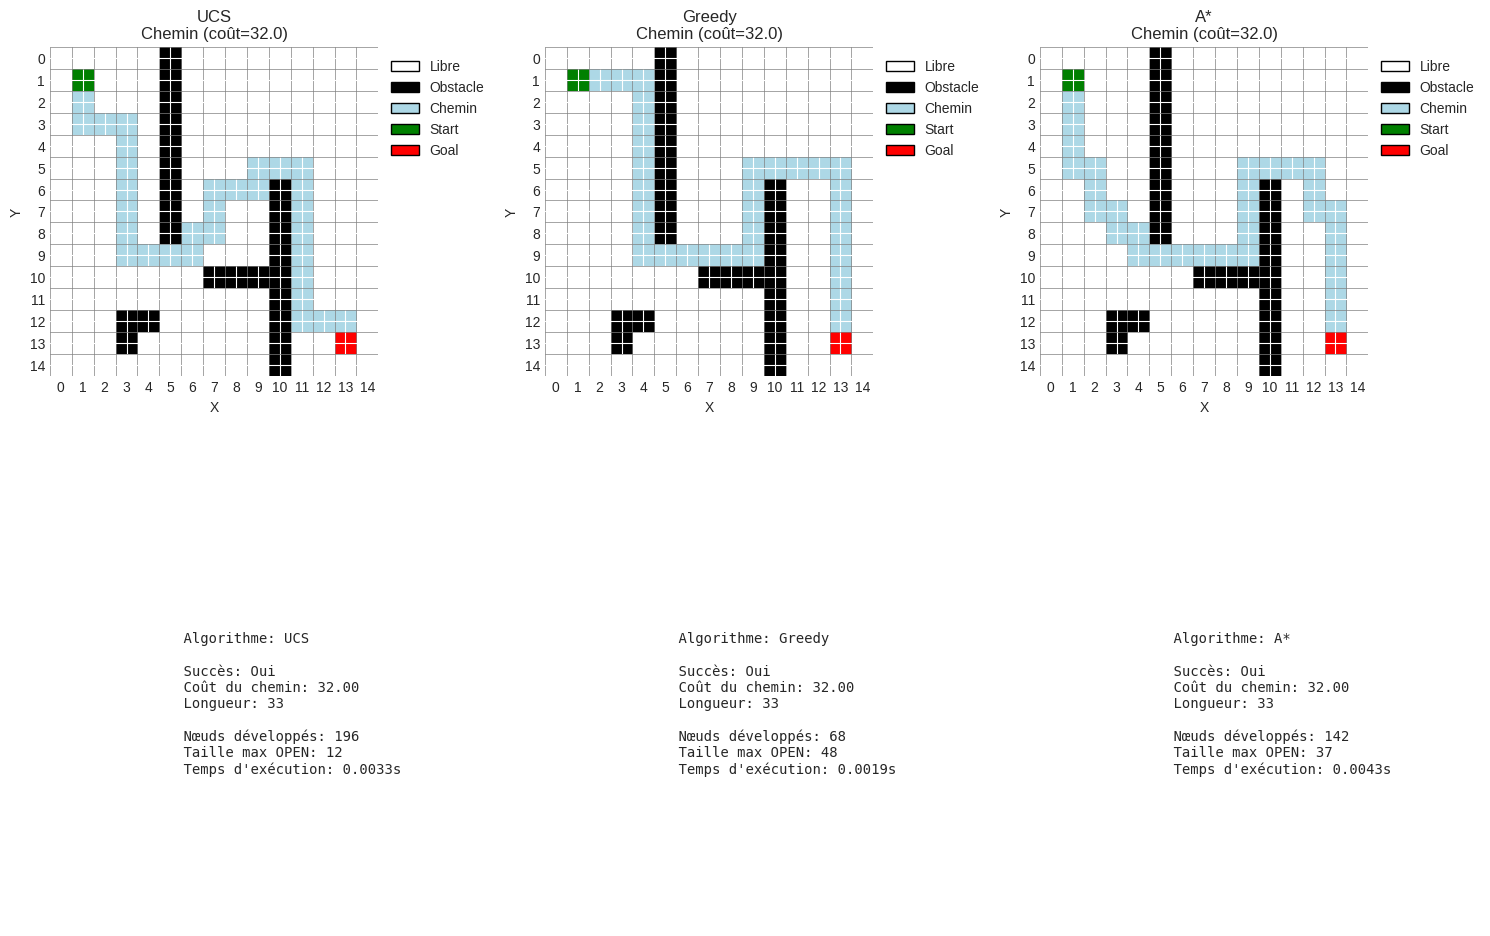


--- Grille Difficile (20x20) ---
UCS     : coût=  42.0, nœuds=  290, temps=0.0021s
Greedy  : coût=  42.0, nœuds=   79, temps=0.0008s
A*      : coût=  42.0, nœuds=  220, temps=0.0031s
  → Visualisation pour grille Difficile...


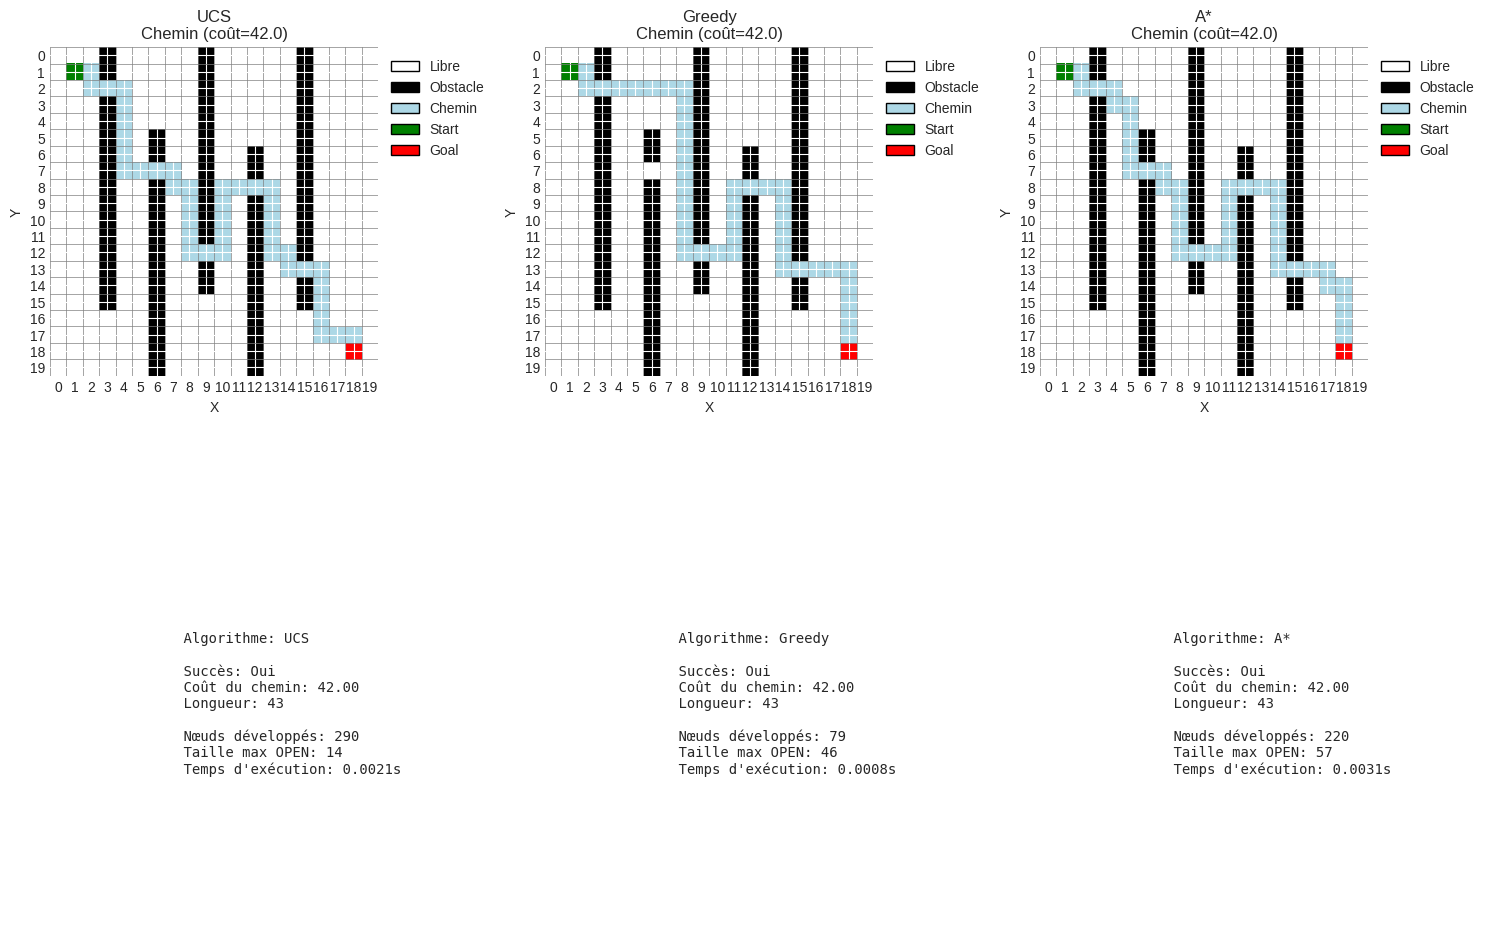


TABLEAU RÉCAPITULATIF E.1
   Grille Algorithme  Succès  Coût  Longueur  Nœuds développés  Max OPEN  Temps (s)
   Facile        UCS    True  14.0        15                88        13   0.001535
   Facile     Greedy    True  14.0        15                14        28   0.000737
   Facile         A*    True  14.0        15                38        35   0.001923
  Moyenne        UCS    True  32.0        33               196        12   0.003268
  Moyenne     Greedy    True  32.0        33                68        48   0.001874
  Moyenne         A*    True  32.0        33               142        37   0.004251
Difficile        UCS    True  42.0        43               290        14   0.002062
Difficile     Greedy    True  42.0        43                79        46   0.000826
Difficile         A*    True  42.0        43               220        57   0.003132

✓ Résultats sauvegardés dans 'results_E1.csv'


In [21]:
exp1 = E1_CompareAlgorithms()
df_e1 = exp1.run()

### E.2: Variation d'epsilon

In [ ]:
from generate_grids_figures import Visualizer

# Créer une instance du visualiseur
vis = Visualizer()

# Générer toutes les figures (sauvegardées dans figures/)
vis.generate_all_figures()

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from PIL import Image
import os

# Afficher un aperçu des figures générées
figures = [
    ("grid_simple.png", "Grille Simple"),
    ("grid_medium.png", "Grille Moyenne"),
    ("grid_hard.png", "Grille Difficile"),
    ("grid_algorithm_comparison.png", "Comparaison Algorithmes"),
    ("grid_path_length_comparison.png", "Comparaison Longueurs"),
]

print("=" * 80)
print(" " * 20 + "FIGURES GÉNÉRÉES")
print("=" * 80)

for filename, title in figures:
    filepath = os.path.join("figures", filename)
    if os.path.exists(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"✓ {title}: {filename} ({size_kb:.0f} KB)")
    else:
        print(f"✗ {title}: {filename} (NOT FOUND)")

print("\nToutes les figures sont prêtes pour le rapport LaTeX!")
print("Style cohérent avec matplotlib seaborn-v0_8-paper (300 DPI)")

# Visualiser les grilles

In [ ]:
exp2 = E2_VaryEpsilon()
df_e2 = exp2.run(grid=medium_grid, epsilons=[0.0, 0.05, 0.1, 0.15, 0.2, 0.3], n_simulations=1000)

### E.3: Comparaison d'heuristiques

In [ ]:
exp3 = E3_CompareHeuristics()
df_e3 = exp3.run(grid=medium_grid)

### E.4: Weighted A*

In [ ]:
exp4 = E4_WeightedAStar()
df_e4 = exp4.run(grid=hard_grid, weights=[1.0, 1.5, 2.0, 2.5, 3.0])

## 8. Synthèse et Conclusion

In [ ]:
print("=" * 70)
print(" " * 25 + "SYNTHÈSE FINALE")
print("=" * 70)

print("\n1. ALGORITHMES DE RECHERCHE")
print("   - A* trouve le chemin optimal avec une heuristique admissible")
print("   - Manhattan réduit significativement les expansions vs UCS")
print("   - Greedy est rapide mais non optimal")

print("\n2. MODÉLISATION MARKOV")
print("   - La matrice P capture l'incertitude des actions")
print("   - π(n) converge vers la probabilité d'absorption")
print("   - Les états GOAL et FAIL sont absorbants")

print("\n3. SIMULATION MONTE-CARLO")
print("   - Valide les prédictions théoriques")
print("   - L'incertitude (ε) dégrade les performances")
print("   - Le plan déterministe != performance réelle")

print("\n4. PISTES D'AMÉLIORATION")
print("   - Re-planification dynamique")
print("   - Heuristiques apprises")
print("   - Planification stochastique directe (MDP)")
print("   - Weighted A* pour compromis vitesse/optimalité")